# RTH vs PM2.5 Surabaya — Peta Spasial Per Kecamatan + Analisis Temporal (hybrid)
**Belum pernah dijalankan oleh penyusunnya (hanya dicek sintaks).** Jalankan sel 1 → 11 berurutan.

**Sebelum mulai**
1. **Data penduduk & kepadatan BPS 2024 sudah tertanam di sel 4** (CSV unduhan BPS *"Population, Population Growth Rate, … Density … by Subdistrict in Surabaya Municipality, 2024"*; 31 kecamatan, total 3.017.800 jiwa ≈ total kota BPS 3.018,0 ribu; luas = penduduk ÷ kepadatan). Bila `hasil_spasial/bps_kecamatan_surabaya_2024.csv` sudah ada dan terisi, file itu yang dipakai. Tidak ada data yang disimulasikan; **cek 3-4 baris ke halaman tabel BPS sebelum publikasi.**
2. Batas kecamatan: letakkan `kecamatan_surabaya.geojson` di folder kerja (kolom nama: `kecamatan`/`WADMKC`/`NAME_3`), atau biarkan sel 2 mencoba mengunduh GADM.
3. Peta spasial = **tekanan ruang hijau** (tutupan hijau satelit × kepadatan penduduk). **Bukan peta polusi**: PM2.5 hanya punya satu titik model.
4. Tutupan hijau satelit **bukan RTH resmi** (halaman pribadi, sawah, tambak ikut terhitung).
5. Atribusi: *Weather data by Open-Meteo.com* (CC BY 4.0); ESA WorldCover 2021 v200 (CC BY 4.0); penduduk & kepadatan: BPS Kota Surabaya 2024; batas administrasi sesuai sumber yang dipakai (GADM / OSM).
6. **Tahun data berbeda-beda** (tutupan hijau 2021, penduduk 2024, RTH resmi 2025, PM2.5 2023-2026): tulis di catatan data infografis.

In [ ]:
# @title 1. Setup & konfigurasi
import sys, subprocess, os, re, time, json, zipfile, difflib
from pathlib import Path
from datetime import date, timedelta

def _pastikan(paket, impor):
    try:
        __import__(impor)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=False)

for _p, _i in [("geopandas", "geopandas"), ("rasterio", "rasterio"), ("shapely", "shapely"),
               ("scikit-learn", "sklearn"), ("statsmodels", "statsmodels"), ("seaborn", "seaborn"),
               ("requests", "requests"), ("matplotlib", "matplotlib")]:
    _pastikan(_p, _i)

import numpy as np, pandas as pd, requests
import geopandas as gpd, rasterio
from rasterio import features
from rasterio.windows import Window, from_bounds
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

OUT = Path("hasil_spasial"); OUT.mkdir(exist_ok=True)
DATA = Path("data_cache"); DATA.mkdir(exist_ok=True)

FILE_BATAS_LOKAL = Path("kecamatan_surabaya.geojson")   # opsional: batas kecamatan buatanmu / BIG / OSM
URL_GADM_L3 = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_3.json.zip"   # URL dari ingatan; verifikasi

KEC_RESMI = ["Karangpilang", "Wonocolo", "Rungkut", "Wonokromo", "Tegalsari", "Sawahan", "Genteng",
             "Gubeng", "Sukolilo", "Tambaksari", "Simokerto", "Pabean Cantian", "Bubutan", "Tandes",
             "Krembangan", "Semampir", "Kenjeran", "Lakarsantri", "Benowo", "Wiyung", "Dukuh Pakis",
             "Gayungan", "Jambangan", "Tenggilis Mejoyo", "Gunung Anyar", "Mulyorejo", "Sukomanunggal",
             "Asemrowo", "Bulak", "Pakal", "Sambikerep"]          # 31 kecamatan

# Kelas ESA WorldCover: 10 pohon, 20 semak, 30 rumput, 40 lahan tani, 50 bangunan, 80 air, 90 lahan basah herba, 95 mangrove
HIJAU_INTI = (10, 20, 30, 95)
HIJAU_LUAS = HIJAU_INTI + (40, 90)                  # + lahan tani & lahan basah (termasuk sawah/tambak vegetasi)
KOL_HIJAU = "pct_hijau_inti_daratan"                # ukuran hijau utama untuk klaster & peta
print("Setup selesai. Kecamatan resmi:", len(KEC_RESMI))

Setup selesai. Kecamatan resmi: 31


Mengunduh batas GADM level 3 Indonesia (berkas besar, sabar) ...
31 kecamatan terbaca. Hilang: tidak ada


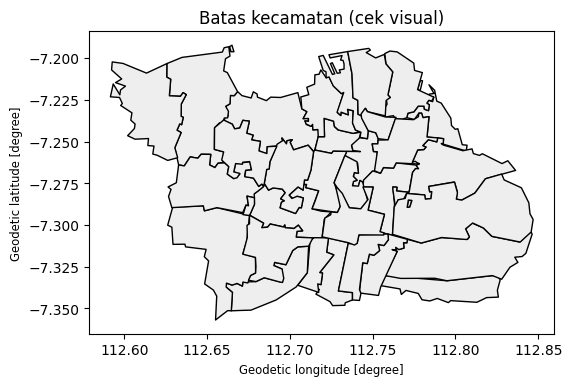

In [ ]:
# @title 2. Batas administrasi 31 kecamatan
def norm(s):
    s = re.sub(r"^\s*(kecamatan|kec\.?)\s+", "", str(s), flags=re.I)   # "Kecamatan Tegalsari" -> "Tegalsari"
    return re.sub(r"[^a-z]", "", s.lower())

KEC_NORM = {norm(k): k for k in KEC_RESMI}

def cocokkan(nama):
    n = norm(nama)
    if n in KEC_NORM:
        return KEC_NORM[n]
    m = difflib.get_close_matches(n, list(KEC_NORM), n=1, cutoff=0.8)
    return KEC_NORM[m[0]] if m else None

KOLOM_NAMA = ["kecamatan", "KECAMATAN", "Kecamatan", "WADMKC", "NAME_3", "name", "nama"]

def muat_batas():
    if FILE_BATAS_LOKAL.exists():
        g = gpd.read_file(FILE_BATAS_LOKAL)
        print("Batas dari file lokal:", FILE_BATAS_LOKAL)
    else:
        f_zip = DATA / "gadm41_IDN_3.json.zip"
        try:
            if not f_zip.exists():
                print("Mengunduh batas GADM level 3 Indonesia (berkas besar, sabar) ...")
                r = requests.get(URL_GADM_L3, stream=True, timeout=600)
                r.raise_for_status()
                with open(f_zip, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            with zipfile.ZipFile(f_zip) as z:
                nm = [n for n in z.namelist() if n.lower().endswith(".json")][0]
                z.extract(nm, DATA)
            g = gpd.read_file(DATA / nm)
        except Exception as e:
            print(f"GADM gagal ({str(e)[:80]}). Mencoba OpenStreetMap (osmnx; admin_level=6 = kecamatan) ...")
            try:
                _pastikan("osmnx", "osmnx")
                import osmnx as ox
                g = ox.features_from_place("Surabaya, East Java, Indonesia",
                                           tags={"boundary": "administrative", "admin_level": "6"})
                g = g[g.geometry.type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)
            except Exception as e2:
                raise RuntimeError(
                    f"Gagal mengambil batas dari GADM ({str(e)[:80]}) maupun OSM ({str(e2)[:80]}). "
                    f"Unduh batas kecamatan Surabaya secara manual (GADM level 3 / BIG / OSM), "
                    f"simpan sebagai {FILE_BATAS_LOKAL}, lalu jalankan ulang sel ini.")
        k2 = [c for c in g.columns if c.upper() == "NAME_2"]
        if k2:
            g = g[g[k2[0]].astype(str).str.contains("surabaya", case=False)]
    kol = next((c for c in KOLOM_NAMA if c in g.columns), None)
    if kol is None:
        raise RuntimeError(f"Kolom nama kecamatan tidak ditemukan. Kolom tersedia: {list(g.columns)}")
    g = g.to_crs(4326) if g.crs else g.set_crs(4326)
    g["kecamatan"] = g[kol].map(cocokkan)
    tak = g[g["kecamatan"].isna()][kol].tolist()
    if tak:
        print("Nama tidak cocok (diabaikan):", tak)
    g = g.dropna(subset=["kecamatan"])
    g = g.dissolve(by="kecamatan", as_index=False)[["kecamatan", "geometry"]]
    hilang = sorted(set(KEC_RESMI) - set(g["kecamatan"]))
    print(f"{len(g)} kecamatan terbaca. Hilang: {hilang if hilang else 'tidak ada'}")
    return g

kec = muat_batas()
if len(kec) != 31:
    print("PERINGATAN: jumlah kecamatan bukan 31 -> periksa sumber batas / ejaan nama.")
kec.plot(edgecolor="black", facecolor="#eeeeee", figsize=(6, 6)); plt.title("Batas kecamatan (cek visual)"); plt.show()

In [ ]:
# @title 3. Estimasi tutupan hijau per kecamatan (ESA WorldCover 10 m, 2021)
def nama_tile(lat, lon):
    la, lo = int(np.floor(lat / 3) * 3), int(np.floor(lon / 3) * 3)
    return f"{'N' if la >= 0 else 'S'}{abs(la):02d}{'E' if lo >= 0 else 'W'}{abs(lo):03d}"

minx, miny, maxx, maxy = kec.total_bounds
t1, t2 = nama_tile(miny, minx), nama_tile(maxy, maxx)
assert t1 == t2, f"Batas melintasi dua tile ({t1}, {t2}); perlu menggabungkan tile."
WC_URL = ("https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/"
          f"ESA_WorldCover_10m_2021_v200_{t1}_Map.tif")   # pola URL dari ingatan; verifikasi bila gagal
print("Tile WorldCover:", t1)

f_zonal = OUT / "tutupan_hijau_kecamatan.csv"
if f_zonal.exists():
    zon = pd.read_csv(f_zonal)
    print("Memakai hasil tersimpan:", f_zonal)
else:
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif"):
        with rasterio.open(WC_URL) as src:
            w = from_bounds(minx, miny, maxx, maxy, transform=src.transform)
            win = Window(int(np.floor(w.col_off)), int(np.floor(w.row_off)),
                         int(np.ceil(w.width)) + 1, int(np.ceil(w.height)) + 1)
            arr = src.read(1, window=win)
            tr = src.window_transform(win)
    print("Raster terbaca:", arr.shape)
    rows = []
    for _, r in kec.iterrows():
        m = features.geometry_mask([r.geometry], out_shape=arr.shape, transform=tr, invert=True)
        v = arr[m].astype(np.int64)
        cnt = np.bincount(v, minlength=101)
        tot, air = int(v.size), int(cnt[80])
        darat = tot - air
        inti = int(cnt[list(HIJAU_INTI)].sum()); luas = int(cnt[list(HIJAU_LUAS)].sum())
        rows.append({"kecamatan": r["kecamatan"], "px_total": tot, "pct_air": 100 * air / tot if tot else np.nan,
                     "pct_pohon_daratan": 100 * cnt[10] / darat if darat else np.nan,
                     "pct_bangunan_daratan": 100 * cnt[50] / darat if darat else np.nan,
                     "pct_hijau_inti_daratan": 100 * inti / darat if darat else np.nan,
                     "pct_hijau_luas_daratan": 100 * luas / darat if darat else np.nan})
    zon = pd.DataFrame(rows)
    zon.to_csv(f_zonal, index=False)
print(zon.sort_values(KOL_HIJAU, ascending=False).round(1).to_string(index=False))
print("\nCATATAN: ini estimasi tutupan vegetasi satelit (2021), BUKAN luas RTH resmi. Kecamatan dengan pct_air tinggi: baca dengan hati-hati.")

Tile WorldCover: S09E111
Raster terbaca: (1977, 3065)
       kecamatan  px_total  pct_air  pct_pohon_daratan  pct_bangunan_daratan  pct_hijau_inti_daratan  pct_hijau_luas_daratan
        Sukolilo    339942     19.0               10.9                  45.4                    43.8                    54.0
     Lakarsantri    262981      0.3               24.5                  41.9                    40.9                    57.8
      Sambikerep    185810      0.0               26.6                  48.5                    40.8                    51.3
     Dukuh Pakis    125022      0.7               26.9                  59.1                    40.3                    40.7
         Rungkut    265650     11.7                6.8                  50.9                    38.3                    49.0
    Gunung Anyar    114042      9.5                6.8                  56.4                    35.8                    42.8
       Mulyorejo    190255     10.1               10.7                 

In [ ]:
# @title 4. Gabung dengan data BPS (kepadatan penduduk)
BPS_CSV = OUT / "bps_kecamatan_surabaya_2024.csv"    # nama baru: tidak bentrok dengan CSV 2023 versi lama
TAHUN_BPS = 2024

# Tabel BPS Kota Surabaya (Statistical Data): "Penduduk, Laju Pertumbuhan Penduduk, Distribusi Persentase, Kepadatan,
# Rasio Jenis Kelamin menurut Kecamatan di Kota Surabaya, 2024" (CSV unduhan BPS). Penduduk dalam RIBUAN (1 desimal);
# kepadatan jiwa/km2. Luas diturunkan = penduduk / kepadatan (bukan angka luas terbitan).
# Total 31 kecamatan = 3.017.800 jiwa (total kota BPS: 3.018,0 ribu; kepadatan kota 8.995).
BPS_2024 = [
    ("Karangpilang", 75.5, 8041), ("Jambangan", 54.2, 13222), ("Gayungan", 43.8, 7444), ("Wonocolo", 80.0, 12256),
    ("Tenggilis Mejoyo", 58.9, 10143), ("Gunung Anyar", 62.3, 6142), ("Rungkut", 123.7, 5397), ("Sukolilo", 115.9, 3845),
    ("Mulyorejo", 88.2, 5079), ("Gubeng", 132.4, 16757), ("Wonokromo", 153.6, 18591), ("Dukuh Pakis", 59.3, 5784),
    ("Wiyung", 76.5, 6179), ("Lakarsantri", 65.0, 3440), ("Sambikerep", 69.1, 4023), ("Tandes", 91.8, 9234),
    ("Sukomanunggal", 104.2, 11237), ("Sawahan", 198.5, 27648), ("Tegalsari", 97.5, 22624), ("Genteng", 58.2, 14339),
    ("Tambaksari", 227.0, 25309), ("Kenjeran", 185.3, 21774), ("Bulak", 47.8, 7667), ("Simokerto", 92.1, 35271),
    ("Semampir", 183.3, 20254), ("Pabean Cantian", 73.9, 13491), ("Bubutan", 96.7, 24860), ("Krembangan", 114.9, 13357),
    ("Asemrowo", 48.8, 3245), ("Benowo", 74.9, 2813), ("Pakal", 64.5, 3474),
]

buat_ulang = not BPS_CSV.exists()
if BPS_CSV.exists():
    _c = pd.read_csv(BPS_CSV)
    if "penduduk" not in _c.columns or _c["penduduk"].isna().any():
        print("CSV BPS lama kosong/tidak lengkap -> ditimpa dengan data tertanam (BPS 2024).")
        buat_ulang = True
if buat_ulang:
    _b = pd.DataFrame(BPS_2024, columns=["kecamatan", "penduduk_ribu", "kepadatan_bps"])
    _b["penduduk"] = (_b["penduduk_ribu"] * 1000).round().astype(int)
    _b["luas_km2"] = (_b["penduduk"] / _b["kepadatan_bps"]).round(2)
    _b["tahun_data"] = TAHUN_BPS
    _b[["kecamatan", "luas_km2", "penduduk", "tahun_data", "kepadatan_bps"]].to_csv(BPS_CSV, index=False)
    print(f"CSV BPS {TAHUN_BPS} dibuat dari data tertanam: {BPS_CSV} | total penduduk = {_b['penduduk'].sum():,}")
else:
    print("Memakai CSV BPS yang sudah ada:", BPS_CSV)

bps = pd.read_csv(BPS_CSV)
bps["kecamatan"] = bps["kecamatan"].map(cocokkan)
if bps["kecamatan"].isna().any() or bps["kecamatan"].duplicated().any():
    raise RuntimeError("Nama kecamatan di CSV BPS tidak cocok/duplikat. Periksa ejaan.")
if bps["penduduk"].isna().any():
    raise RuntimeError("Kolom 'penduduk' masih ada yang kosong. Lengkapi 31 baris dari BPS.")

kec_luas = kec.to_crs(32749).assign(luas_geom_km2=lambda d: d.geometry.area / 1e6)[["kecamatan", "luas_geom_km2"]]
bps = bps.merge(kec_luas, on="kecamatan", how="left")
if bps["luas_km2"].isna().any():
    print("Beberapa luas_km2 kosong -> dipakai luas dari geometri (bisa termasuk area laut).")
    bps["luas_km2"] = bps["luas_km2"].fillna(bps["luas_geom_km2"])
bps["kepadatan"] = bps["penduduk"] / bps["luas_km2"]
bps["log_kepadatan"] = np.log10(bps["kepadatan"])

kdf = kec.merge(zon, on="kecamatan").merge(bps[["kecamatan", "luas_km2", "penduduk", "tahun_data", "kepadatan", "log_kepadatan"]],
                                           on="kecamatan")
print(f"{len(kdf)} kecamatan | total penduduk = {kdf['penduduk'].sum():,.0f} | tahun data BPS: {sorted(kdf['tahun_data'].dropna().unique())}")
print(kdf[["kecamatan", "penduduk", "luas_km2", "kepadatan", KOL_HIJAU]].sort_values("kepadatan", ascending=False).round(1).to_string(index=False))

CSV BPS 2024 dibuat dari data tertanam: hasil_spasial/bps_kecamatan_surabaya_2024.csv | total penduduk = 3,017,800
31 kecamatan | total penduduk = 3,017,800 | tahun data BPS: [np.int64(2024)]
       kecamatan  penduduk  luas_km2  kepadatan  pct_hijau_inti_daratan
       Simokerto     92100       2.6    35287.4                     4.8
         Sawahan    198500       7.2    27646.2                     6.7
      Tambaksari    227000       9.0    25306.6                     4.8
         Bubutan     96700       3.9    24858.6                     6.7
       Tegalsari     97500       4.3    22621.8                     4.2
        Kenjeran    185300       8.5    21774.4                    11.6
        Semampir    183300       9.0    20254.1                    20.5
       Wonokromo    153600       8.3    18595.6                     9.4
          Gubeng    132400       7.9    16759.5                     4.9
         Genteng     58200       4.1    14335.0                     6.7
  Pabean Cantian

In [ ]:
# @title 5. K-Means spasial (K=3): tekanan ruang hijau
FITUR_SPASIAL = [KOL_HIJAU, "log_kepadatan"]
if kdf[FITUR_SPASIAL].isna().any().any():
    print("PERINGATAN: ada NaN pada fitur spasial (mis. kecamatan tanpa daratan) -> diisi median.")
    kdf[FITUR_SPASIAL] = kdf[FITUR_SPASIAL].fillna(kdf[FITUR_SPASIAL].median())
Z = StandardScaler().fit_transform(kdf[FITUR_SPASIAL])

print("Sanity check (n=31, kecil): silhouette per K")
for k in range(2, 6):
    lab = KMeans(n_clusters=k, n_init=50, random_state=42).fit_predict(Z)
    print(f"  K={k}: silhouette = {silhouette_score(Z, lab):.3f}")

km3 = KMeans(n_clusters=3, n_init=50, random_state=42).fit(Z)     # K=3 sesuai desain infografis
kdf["klaster_id"] = km3.labels_
kdf["z_hijau"], kdf["z_padat"] = Z[:, 0], Z[:, 1]
kdf["indeks_tekanan"] = kdf["z_padat"] - kdf["z_hijau"]           # tinggi = padat & minim hijau

urut = kdf.groupby("klaster_id")["indeks_tekanan"].mean().sort_values(ascending=False).index.tolist()
NAMA = {urut[0]: "Tekanan tinggi: padat & minim hijau",
        urut[1]: "Menengah",
        urut[2]: "Tekanan rendah: lebih hijau & renggang"}
WARNA = {NAMA[urut[0]]: "#d73027", NAMA[urut[1]]: "#fee08b", NAMA[urut[2]]: "#1a9850"}
kdf["klaster_nama"] = kdf["klaster_id"].map(NAMA)

ring = (kdf.groupby("klaster_nama").agg(n_kec=("kecamatan", "size"), hijau_pct=(KOL_HIJAU, "mean"),
                                         kepadatan=("kepadatan", "mean"), penduduk=("penduduk", "sum"))
        .round(1).loc[list(NAMA.values())])
ring["pct_penduduk"] = (ring["penduduk"] / kdf["penduduk"].sum() * 100).round(1)
print("\nRingkasan klaster:"); print(ring.to_string())
for n in NAMA.values():
    print(f"\n[{n}]", ", ".join(sorted(kdf.loc[kdf.klaster_nama == n, "kecamatan"])))

# Uji kestabilan: ganti definisi hijau (inti -> luas)
Z2 = StandardScaler().fit_transform(kdf[["pct_hijau_luas_daratan", "log_kepadatan"]])
lab2 = KMeans(n_clusters=3, n_init=50, random_state=42).fit_predict(Z2)
print(f"\nKestabilan klaster terhadap definisi hijau (ARI, 1 = identik): {adjusted_rand_score(kdf['klaster_id'], lab2):.2f}")

Sanity check (n=31, kecil): silhouette per K
  K=2: silhouette = 0.582
  K=3: silhouette = 0.505
  K=4: silhouette = 0.472
  K=5: silhouette = 0.445

Ringkasan klaster:
                                        n_kec  hijau_pct  kepadatan  penduduk  pct_penduduk
klaster_nama                                                                               
Tekanan tinggi: padat & minim hijau        16        9.2    18820.9   1910700          63.3
Menengah                                    5       17.8     5243.0    323800          10.7
Tekanan rendah: lebih hijau & renggang     10       36.0     5560.3    783300          26.0

[Tekanan tinggi: padat & minim hijau] Bubutan, Genteng, Gubeng, Jambangan, Kenjeran, Krembangan, Pabean Cantian, Sawahan, Semampir, Simokerto, Sukomanunggal, Tambaksari, Tegalsari, Tenggilis Mejoyo, Wonocolo, Wonokromo

[Menengah] Asemrowo, Benowo, Gayungan, Pakal, Tandes

[Tekanan rendah: lebih hijau & renggang] Bulak, Dukuh Pakis, Gunung Anyar, Karangpilang, Lakarsa

In [ ]:
# @title 5b. Uji stabilitas klaster terhadap ketidakpastian data (Monte Carlo)
# Menjawab: "apakah klaster berubah bila data penduduk BPS / estimasi hijau satelit meleset beberapa persen?"
N_SIM = 300
NOISE_PADAT, NOISE_HIJAU = 0.10, 0.10          # ketidakpastian relatif (+-10%)
rng = np.random.default_rng(42)

def peringkat_klaster(df_in):
    # -> (peringkat per kecamatan: 0 = tekanan tertinggi ... 2 = terendah, label mentah)
    Zs = StandardScaler().fit_transform(df_in[FITUR_SPASIAL])
    lab = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(Zs)
    skor = pd.Series(Zs[:, 1] - Zs[:, 0]).groupby(lab).mean().sort_values(ascending=False)
    peringkat = {c: r for r, c in enumerate(skor.index)}
    return np.array([peringkat[c] for c in lab]), lab

base_rank = kdf["klaster_nama"].map({NAMA[urut[i]]: i for i in range(3)}).values
sama = np.zeros(len(kdf)); ari = []
for _ in range(N_SIM):
    d = pd.DataFrame({
        KOL_HIJAU: kdf[KOL_HIJAU].values * rng.uniform(1 - NOISE_HIJAU, 1 + NOISE_HIJAU, len(kdf)),
        "log_kepadatan": np.log10(kdf["kepadatan"].values * rng.uniform(1 - NOISE_PADAT, 1 + NOISE_PADAT, len(kdf)))})
    r, lab = peringkat_klaster(d)
    sama += (r == base_rank)
    ari.append(adjusted_rand_score(kdf["klaster_id"], lab))

stab = pd.DataFrame({"kecamatan": kdf["kecamatan"].values, "klaster": kdf["klaster_nama"].values,
                     "stabilitas_pct": (sama / N_SIM * 100).round(0)}).sort_values("stabilitas_pct")
print(f"{N_SIM} simulasi | noise: kepadatan +-{NOISE_PADAT * 100:.0f}%, hijau +-{NOISE_HIJAU * 100:.0f}%")
print(f"ARI rata-rata terhadap klaster dasar = {np.mean(ari):.2f} (1 = identik) | min = {np.min(ari):.2f}")
print(f"Kecamatan dengan stabilitas >= 90%: {(stab['stabilitas_pct'] >= 90).sum()} dari {len(stab)}")
batas = stab[stab["stabilitas_pct"] < 80]
print("\nKecamatan 'batas klaster' (<80% stabil; tandai/hati-hati di peta):")
print(batas.to_string(index=False) if len(batas) else "tidak ada")
stab.to_csv(OUT / "stabilitas_klaster.csv", index=False)
print("\nBahasa naskah bila ARI tinggi: 'pengelompokan stabil terhadap ketidakpastian data penduduk & tutupan hijau (+-10%)'.")

300 simulasi | noise: kepadatan +-10%, hijau +-10%
ARI rata-rata terhadap klaster dasar = 0.85 (1 = identik) | min = 0.51
Kecamatan dengan stabilitas >= 90%: 26 dari 31

Kecamatan 'batas klaster' (<80% stabil; tandai/hati-hati di peta):
    kecamatan                                klaster  stabilitas_pct
       Wiyung Tekanan rendah: lebih hijau & renggang            43.0
        Bulak Tekanan rendah: lebih hijau & renggang            60.0
Sukomanunggal    Tekanan tinggi: padat & minim hijau            61.0
 Karangpilang Tekanan rendah: lebih hijau & renggang            73.0
       Tandes                               Menengah            78.0

Bahasa naskah bila ARI tinggi: 'pengelompokan stabil terhadap ketidakpastian data penduduk & tutupan hijau (+-10%)'.


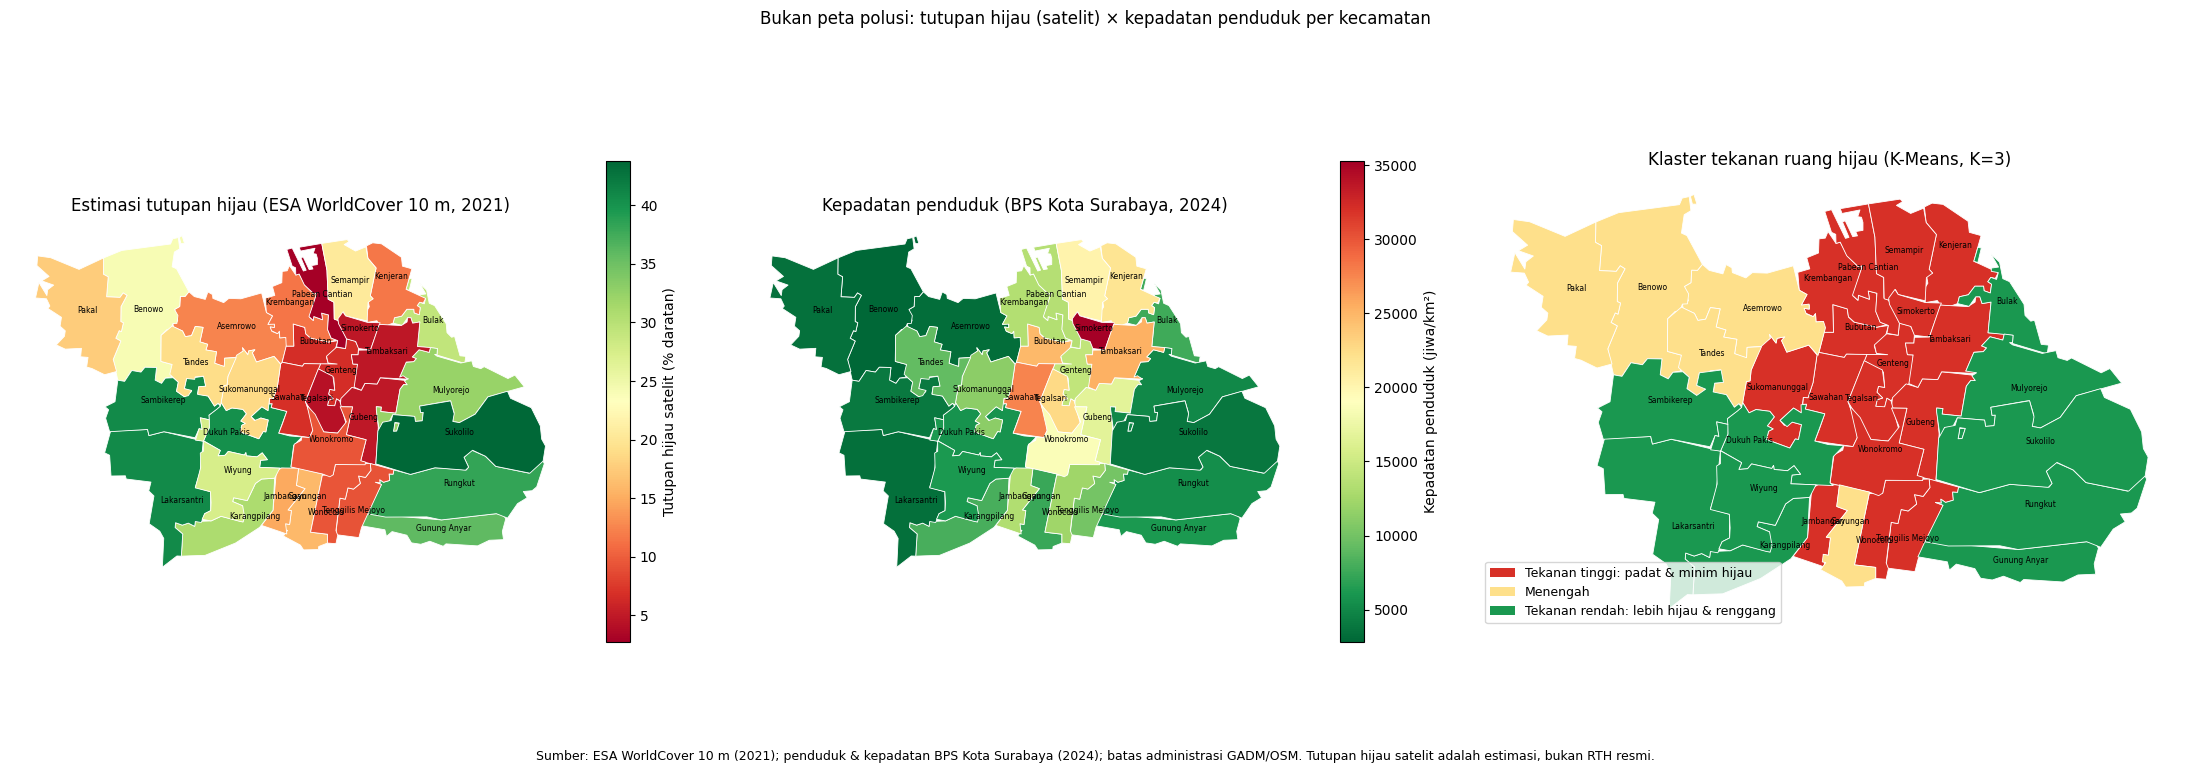

Tersimpan di hasil_spasial


In [ ]:
# @title 6. Peta choropleth 31 kecamatan
fig, ax = plt.subplots(1, 3, figsize=(22, 7.5))

kdf.plot(column=KOL_HIJAU, cmap="RdYlGn", legend=True, ax=ax[0], edgecolor="white", linewidth=0.6,
         legend_kwds={"label": "Tutupan hijau satelit (% daratan)", "shrink": 0.7})
ax[0].set_title("Estimasi tutupan hijau (ESA WorldCover 10 m, 2021)")

kdf.plot(column="kepadatan", cmap="RdYlGn_r", legend=True, ax=ax[1], edgecolor="white", linewidth=0.6,
         legend_kwds={"label": "Kepadatan penduduk (jiwa/km²)", "shrink": 0.7})
ax[1].set_title("Kepadatan penduduk (BPS Kota Surabaya, 2024)")

for n, warna in WARNA.items():
    sub = kdf[kdf["klaster_nama"] == n]
    if len(sub):
        sub.plot(ax=ax[2], color=warna, edgecolor="white", linewidth=0.6)
ax[2].legend(handles=[Patch(facecolor=w, label=n) for n, w in WARNA.items()], loc="lower left", fontsize=9)
ax[2].set_title("Klaster tekanan ruang hijau (K-Means, K=3)")

for a in ax:
    for _, r in kdf.iterrows():
        p = r.geometry.representative_point()
        a.annotate(r["kecamatan"], (p.x, p.y), fontsize=5.5, ha="center")
    a.set_axis_off()
fig.suptitle("Bukan peta polusi: tutupan hijau (satelit) × kepadatan penduduk per kecamatan", y=1.0)
fig.text(0.5, 0.0, "Sumber: ESA WorldCover 10 m (2021); penduduk & kepadatan BPS Kota Surabaya (2024); batas administrasi GADM/OSM. "
         "Tutupan hijau satelit adalah estimasi, bukan RTH resmi.", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "peta_kecamatan.png", dpi=200, bbox_inches="tight"); plt.show()

kdf.to_file(OUT / "kecamatan_klaster.geojson", driver="GeoJSON")     # untuk QGIS / Canva / Figma
kdf.drop(columns="geometry").to_csv(OUT / "kecamatan_klaster.csv", index=False)
print("Tersimpan di", OUT)

In [ ]:
# @title 7. Data Open-Meteo (untuk Bagian B & C) — dilewati bila df_t sudah ada
LAT, LON = -7.2575, 112.7521
MULAI = date(2023, 1, 1); HARI_INI = date.today()
FORCE_REFRESH = False
URL_AQ = "https://air-quality-api.open-meteo.com/v1/air-quality"
URL_CU = "https://archive-api.open-meteo.com/v1/archive"

def ambil_json(url, params, coba=4):
    for i in range(coba):
        try:
            r = requests.get(url, params=params, timeout=120)
            if r.ok:
                js = r.json()
                if js.get("error"):
                    print("   API error:", js.get("reason")); return None
                return js
            print(f"   HTTP {r.status_code}: {r.text[:120]}")
            if r.status_code < 500 and r.status_code != 429:
                return None
        except requests.RequestException as e:
            print("   koneksi gagal:", str(e)[:80])
        time.sleep(2 * (i + 1))
    return None

def aq_tahun(th):
    f = DATA / f"aq_jam_{th}.csv"
    if f.exists() and not FORCE_REFRESH and th < HARI_INI.year:
        return pd.read_csv(f, parse_dates=["time"])
    print(f"[AQ {th}] unduh ...")
    js = ambil_json(URL_AQ, {"latitude": LAT, "longitude": LON, "hourly": "pm2_5",
                             "start_date": date(th, 1, 1).isoformat(),
                             "end_date": min(date(th, 12, 31), HARI_INI).isoformat(), "timezone": "Asia/Jakarta"})
    if not js or "hourly" not in js:
        return pd.DataFrame()
    d = pd.DataFrame(js["hourly"]); d["time"] = pd.to_datetime(d["time"]); d.to_csv(f, index=False)
    return d

def cu_tahun(th):
    a, b = date(th, 1, 1), min(date(th, 12, 31), HARI_INI - timedelta(days=7))
    if a > b:
        return pd.DataFrame()
    f = DATA / f"cuaca_{th}.csv"
    if f.exists() and not FORCE_REFRESH and th < HARI_INI.year:
        return pd.read_csv(f)
    print(f"[Cuaca {th}] unduh ...")
    js = ambil_json(URL_CU, {"latitude": LAT, "longitude": LON, "start_date": a.isoformat(), "end_date": b.isoformat(),
                             "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max", "timezone": "Asia/Jakarta"})
    if not js or "daily" not in js:
        return pd.DataFrame()
    d = pd.DataFrame(js["daily"]); d.to_csv(f, index=False)
    return d

if "df_t" not in globals():
    tahun = range(MULAI.year, HARI_INI.year + 1)
    aq_list = [x for x in (aq_tahun(t) for t in tahun) if not x.empty]
    cu_list = [x for x in (cu_tahun(t) for t in tahun) if not x.empty]
    if not aq_list or not cu_list:
        raise RuntimeError("Gagal mengambil data Open-Meteo (cek internet, jalankan ulang sel ini).")
    aq_jam = pd.concat(aq_list, ignore_index=True)
    aq_jam["tanggal"] = aq_jam["time"].dt.normalize()
    aq = aq_jam.groupby("tanggal").agg(pm2_5_mean=("pm2_5", "mean"), jam=("pm2_5", "count")).reset_index()
    aq = aq[aq["jam"] >= 18]
    cu = pd.concat(cu_list, ignore_index=True); cu["tanggal"] = pd.to_datetime(cu["time"])
    df_t = (aq[["tanggal", "pm2_5_mean"]].merge(cu[["tanggal", "temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max"]],
                                                on="tanggal", how="inner")
            .rename(columns={"pm2_5_mean": "pm25", "temperature_2m_mean": "suhu",
                             "precipitation_sum": "hujan", "wind_speed_10m_max": "angin"})
            .drop_duplicates("tanggal").dropna().sort_values("tanggal").reset_index(drop=True))
print(f"{len(df_t)} hari | {df_t.tanggal.min():%d %b %Y} - {df_t.tanggal.max():%d %b %Y}")
print(f"PM2.5 rata-rata = {df_t.pm25.mean():.2f} | hari >15 = {(df_t.pm25 > 15).sum()} ({(df_t.pm25 > 15).mean() * 100:.1f}%) "
      f"| hari >55 = {(df_t.pm25 > 55).sum()}   [ESTIMASI MODEL CAMS]")

[AQ 2023] unduh ...
[AQ 2024] unduh ...
[AQ 2025] unduh ...
[AQ 2026] unduh ...
[Cuaca 2023] unduh ...
[Cuaca 2024] unduh ...
[Cuaca 2025] unduh ...
[Cuaca 2026] unduh ...
1400 hari | 01 Jan 2023 - 31 Oct 2026
PM2.5 rata-rata = 37.83 | hari >15 = 1352 (96.6%) | hari >55 = 238   [ESTIMASI MODEL CAMS]


K=2 | Silhouette = 0.3743
K=3 | Silhouette = 0.3374
K=4 | Silhouette = 0.2762
K=5 | Silhouette = 0.2661
K=6 | Silhouette = 0.2734
>>> K optimal (silhouette tertinggi) = 2

Profil klaster (nama diberikan dari curah hujan, BUKAN diasumsikan):
                     n_hari   pm25   suhu  hujan_mm  angin
kl_t                                                      
Kering & berangin       775  30.29  28.64      0.53  18.01
Basah & angin lemah     625  47.19  27.23     10.05  12.50
Periksa kolom pm25: klaster mana yang lebih pekat menurut model.


/tmp/ipykernel_2500/2328304810.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_t, x="profil_t", y="pm25", ax=ax[1], palette="coolwarm")


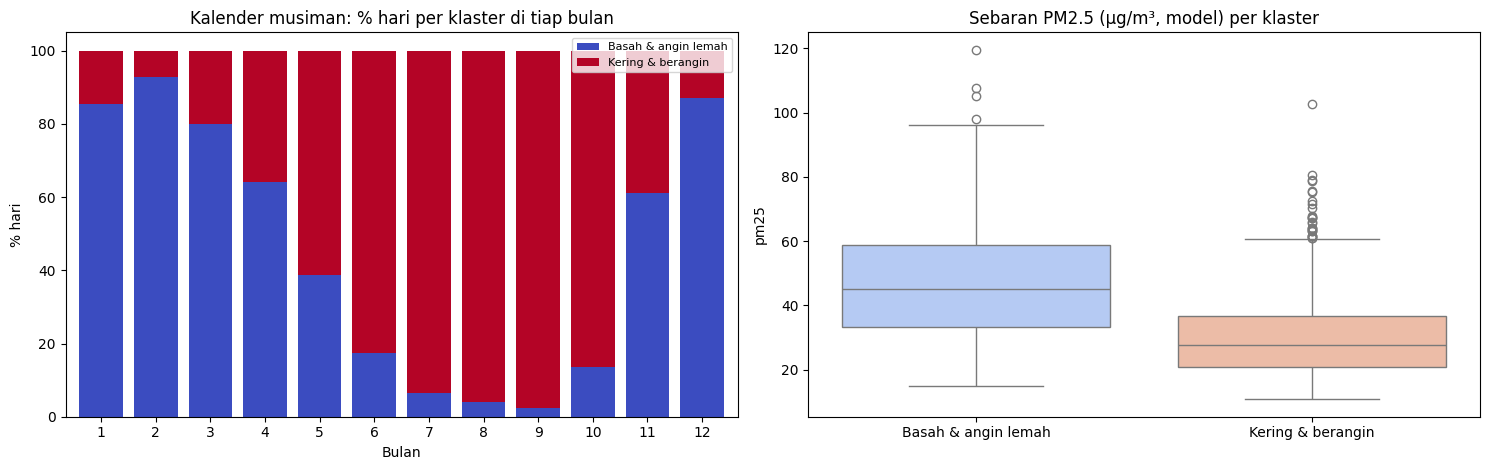

In [ ]:
# @title 8. Bagian B — Temporal K-Means (K dipilih silhouette; klaster dinamai dari data)
FITUR_T = ["pm25", "suhu", "hujan", "angin"]
Xt = df_t[FITUR_T].copy(); Xt["hujan"] = np.log1p(Xt["hujan"])
Zt = StandardScaler().fit_transform(Xt)

sils = {}
for k in range(2, 7):
    lab = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Zt)
    sils[k] = silhouette_score(Zt, lab)
    print(f"K={k} | Silhouette = {sils[k]:.4f}")
K_T = max(sils, key=sils.get)
print(f">>> K optimal (silhouette tertinggi) = {K_T}")

df_t["kl_t"] = KMeans(n_clusters=K_T, n_init=20, random_state=42).fit_predict(Zt)
prof = df_t.groupby("kl_t").agg(n_hari=("pm25", "size"), pm25=("pm25", "mean"), suhu=("suhu", "mean"),
                                hujan_mm=("hujan", "mean"), angin=("angin", "mean")).round(2)
urut_t = prof.sort_values("hujan_mm").index.tolist()
if K_T == 2:
    nama_t = {urut_t[0]: "Kering & berangin", urut_t[1]: "Basah & angin lemah"}
else:
    nama_t = {k: f"Klaster {i + 1} (hujan {prof.loc[k, 'hujan_mm']:.1f} mm)" for i, k in enumerate(urut_t)}
df_t["profil_t"] = df_t["kl_t"].map(nama_t)
prof.index = prof.index.map(nama_t)
print("\nProfil klaster (nama diberikan dari curah hujan, BUKAN diasumsikan):"); print(prof.to_string())
print("Periksa kolom pm25: klaster mana yang lebih pekat menurut model.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
(pd.crosstab(df_t["tanggal"].dt.month, df_t["profil_t"], normalize="index") * 100).plot(
    kind="bar", stacked=True, ax=ax[0], colormap="coolwarm", width=0.8)
ax[0].set_title("Kalender musiman: % hari per klaster di tiap bulan"); ax[0].set_xlabel("Bulan"); ax[0].set_ylabel("% hari")
ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=df_t, x="profil_t", y="pm25", ax=ax[1], palette="coolwarm")
ax[1].set_title("Sebaran PM2.5 (µg/m³, model) per klaster"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "temporal_klaster.png", dpi=200, bbox_inches="tight"); plt.show()

Latih Jan 2023-Dec 2025 (36 bln) | Uji Jan 2026-Oct 2026 (10 bln)

Baseline: klimatologi bulanan          R² =   0.491 | MAE =   4.71 | RMSE =   6.35
Holt-Winters (tren teredam)            R² =  -2.166 | MAE =  14.30 | RMSE =  15.85
Holt-Winters (musiman saja)            R² =  -0.991 | MAE =  11.27 | RMSE =  12.57

Peringkat (RMSE terkecil):
                        model     R2    MAE   RMSE
Baseline: klimatologi bulanan  0.491  4.714  6.353
  Holt-Winters (musiman saja) -0.991 11.269 12.570
  Holt-Winters (tren teredam) -2.166 14.300 15.852
CATATAN: n uji kecil & 2025 adalah tahun anomali. Laporkan baseline bila ia mengalahkan Holt-Winters.

Proyeksi musiman (klimatologi bulanan, semua data):
         rata2  min_antartahun  maks_antartahun
tanggal                                        
1         41.2            34.7             49.6
2         36.8            29.5             41.1
3         44.9            37.2             49.6
4         40.7            32.5             53.7
5        

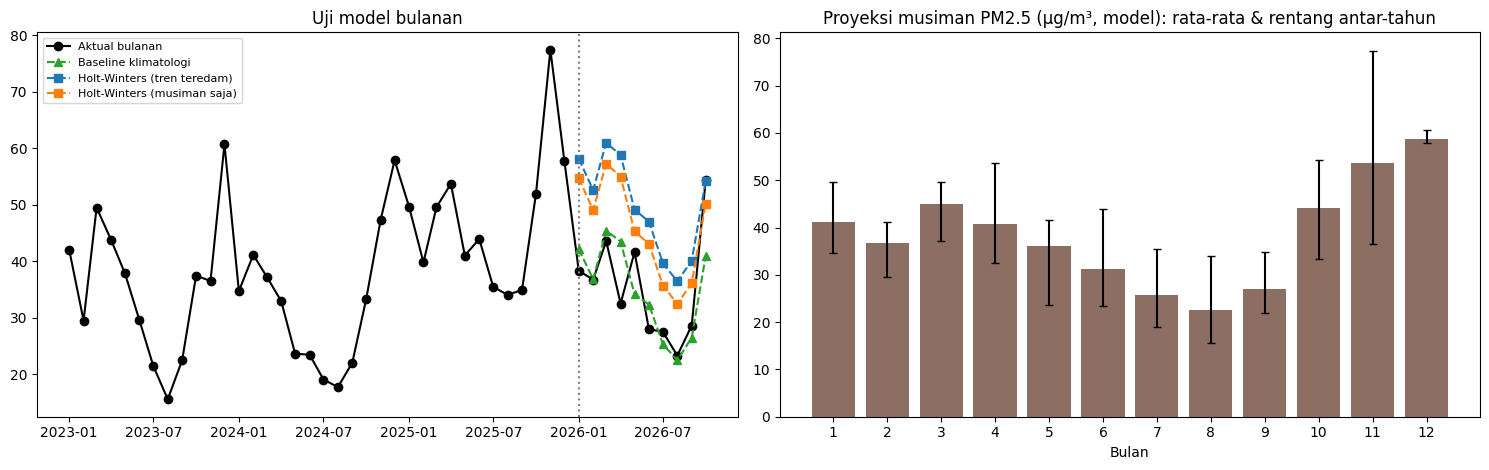

In [ ]:
# @title 9. Bagian C — Holt-Winters vs baseline + proyeksi musiman
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def metrik(y, yhat, nama):
    r2 = r2_score(y, yhat); mae = mean_absolute_error(y, yhat); rmse = np.sqrt(mean_squared_error(y, yhat))
    print(f"{nama:<38} R² = {r2:7.3f} | MAE = {mae:6.2f} | RMSE = {rmse:6.2f}")
    return {"model": nama, "R2": r2, "MAE": mae, "RMSE": rmse}

s = df_t.set_index("tanggal")["pm25"]
cnt = s.resample("MS").count()
m = s.resample("MS").mean()[cnt >= 25]                       # buang bulan tidak lengkap
cm = int(len(m) * 0.8); m_tr, m_te = m.iloc[:cm], m.iloc[cm:]
print(f"Latih {m_tr.index[0]:%b %Y}-{m_tr.index[-1]:%b %Y} ({len(m_tr)} bln) | Uji {m_te.index[0]:%b %Y}-{m_te.index[-1]:%b %Y} ({len(m_te)} bln)\n")

hasil = []
p_base = m_tr.groupby(m_tr.index.month).mean().reindex(m_te.index.month).values
hasil.append(metrik(m_te, p_base, "Baseline: klimatologi bulanan"))
preds = {}
for nama, kw in [("Holt-Winters (tren teredam)", dict(trend="add", damped_trend=True)),
                 ("Holt-Winters (musiman saja)", dict(trend=None))]:
    try:
        fit = ExponentialSmoothing(m_tr, seasonal="add", seasonal_periods=12, **kw).fit()
        preds[nama] = fit.forecast(len(m_te))
        hasil.append(metrik(m_te, preds[nama], nama))
    except Exception as e:
        print(f"{nama}: gagal ({str(e)[:80]})")
tab = pd.DataFrame(hasil).sort_values("RMSE")
print("\nPeringkat (RMSE terkecil):"); print(tab.round(3).to_string(index=False))
print("CATATAN: n uji kecil & 2025 adalah tahun anomali. Laporkan baseline bila ia mengalahkan Holt-Winters.")

# Proyeksi musiman 12 bulan = klimatologi + rentang antar-tahun
clim = m.groupby(m.index.month).agg(["mean", "min", "max"]).round(1)
clim.columns = ["rata2", "min_antartahun", "maks_antartahun"]
print("\nProyeksi musiman (klimatologi bulanan, semua data):"); print(clim.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].plot(m.index, m.values, "o-", c="black", label="Aktual bulanan")
ax[0].plot(m_te.index, p_base, "^--", c="tab:green", label="Baseline klimatologi")
for nama, p in preds.items():
    ax[0].plot(m_te.index, p.values, "s--", label=nama)
ax[0].axvline(m_te.index[0], ls=":", c="gray"); ax[0].set_title("Uji model bulanan"); ax[0].legend(fontsize=8)
ax[1].bar(clim.index, clim["rata2"], color="#8d6e63")
ax[1].errorbar(clim.index, clim["rata2"], yerr=[clim["rata2"] - clim["min_antartahun"], clim["maks_antartahun"] - clim["rata2"]],
               fmt="none", c="black", capsize=3)
ax[1].set_xticks(range(1, 13)); ax[1].set_title("Proyeksi musiman PM2.5 (µg/m³, model): rata-rata & rentang antar-tahun")
ax[1].set_xlabel("Bulan")
plt.tight_layout(); plt.savefig(OUT / "forecast_musiman.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# @title 10. Analisis sensitivitas (aritmetika, BUKAN efek RTH)
def sensitivitas(pm, reduksi=(0, .1, .2, .3, .4, .5, .6)):
    rows = []
    for r in reduksi:
        x = pm * (1 - r)
        rows.append({"reduksi_%": int(r * 100), "rata2": x.mean(), "hari_>15": int((x > 15).sum()),
                     "%hari_>15": (x > 15).mean() * 100, "hari_>55": int((x > 55).sum()), "%hari_>55": (x > 55).mean() * 100})
    return pd.DataFrame(rows).round(1)

sens = sensitivitas(df_t["pm25"]); print(sens.to_string(index=False))
butuh = (1 - 15 / df_t["pm25"].mean()) * 100
print(f"\nReduksi seragam agar RATA-RATA harian <= 15 µg/m³: {butuh:.0f}%  (tidak realistis sebagai target jangka pendek)")
h0, h20 = int(sens.loc[sens["reduksi_%"] == 0, "hari_>55"].iloc[0]), int(sens.loc[sens["reduksi_%"] == 20, "hari_>55"].iloc[0])
print(f"Reduksi 20% memangkas hari >55 µg/m³ dari {h0} menjadi {h20} ({(1 - h20 / h0) * 100:.0f}% lebih sedikit).")
print("Tidak ada klaim bahwa penambahan RTH menghasilkan reduksi tertentu: RTH 2022-2025 nyaris tidak berubah.")

LUAS_KOTA_HA, RTH_2022, RTH_NOW, TAMAN_NOW = 33451.0, 7358.87, 7377.66, 1673.93
gap = 0.30 * LUAS_KOTA_HA - RTH_NOW; laju = (RTH_NOW - RTH_2022) / 3.75
print(f"\nCelah RTH ke 30% = {gap:,.0f} ha | laju {laju:.1f} ha/th -> ~{gap / laju:,.0f} tahun (ilustrasi; 30% mencakup 10% RTH privat)")

 reduksi_%  rata2  hari_>15  %hari_>15  hari_>55  %hari_>55
         0   37.8      1352       96.6       238       17.0
        10   34.1      1311       93.6       166       11.9
        20   30.3      1250       89.3        85        6.1
        30   26.5      1167       83.4        38        2.7
        40   22.7      1035       73.9         9        0.6
        50   18.9       829       59.2         1        0.1
        60   15.1       603       43.1         0        0.0

Reduksi seragam agar RATA-RATA harian <= 15 µg/m³: 60%  (tidak realistis sebagai target jangka pendek)
Reduksi 20% memangkas hari >55 µg/m³ dari 238 menjadi 85 (64% lebih sedikit).
Tidak ada klaim bahwa penambahan RTH menghasilkan reduksi tertentu: RTH 2022-2025 nyaris tidak berubah.

Celah RTH ke 30% = 2,658 ha | laju 5.0 ha/th -> ~530 tahun (ilustrasi; 30% mencakup 10% RTH privat)


In [ ]:
# @title 11. Ringkasan angka untuk naskah (disimpan ke JSON)
rk = {"hari_valid": int(len(df_t)), "pm25_rata2": round(float(df_t.pm25.mean()), 2),
      "hari_gt15": int((df_t.pm25 > 15).sum()), "hari_gt55": int((df_t.pm25 > 55).sum()),
      "K_temporal": int(K_T), "silhouette_temporal": round(float(sils[K_T]), 4),
      "profil_temporal": prof.round(2).to_dict(orient="index"),
      "metrik_bulanan": tab.round(3).to_dict(orient="records"),
      "reduksi_agar_rata2_15_pct": round(float(butuh), 1),
      "hari_gt55_reduksi20": h20}
if "kdf" in globals() and "klaster_nama" in kdf.columns:
    rk["klaster_spasial"] = {n: sorted(kdf.loc[kdf.klaster_nama == n, "kecamatan"]) for n in NAMA.values()}
    rk["hijau_tertinggi"] = kdf.nlargest(3, KOL_HIJAU)[["kecamatan", KOL_HIJAU]].round(1).to_dict(orient="records")
    rk["hijau_terendah"] = kdf.nsmallest(3, KOL_HIJAU)[["kecamatan", KOL_HIJAU]].round(1).to_dict(orient="records")
    rk["terpadat"] = kdf.nlargest(3, "kepadatan")[["kecamatan", "kepadatan"]].round(0).to_dict(orient="records")
    rk["penduduk_di_klaster_tekanan_tinggi_pct"] = float(ring.loc[NAMA[urut[0]], "pct_penduduk"])
if "stab" in globals():
    rk["stabilitas_klaster_rata2_pct"] = round(float(stab["stabilitas_pct"].mean()), 1)
    rk["ARI_rata2"] = round(float(np.mean(ari)), 3)
    rk["kecamatan_batas_klaster"] = stab.loc[stab["stabilitas_pct"] < 80, "kecamatan"].tolist()
with open(OUT / "ringkasan_naskah.json", "w", encoding="utf-8") as fh:
    json.dump(rk, fh, ensure_ascii=False, indent=2, default=str)
print(json.dumps(rk, ensure_ascii=False, indent=2, default=str)[:3500])

{
  "hari_valid": 1400,
  "pm25_rata2": 37.83,
  "hari_gt15": 1352,
  "hari_gt55": 238,
  "K_temporal": 2,
  "silhouette_temporal": 0.3743,
  "profil_temporal": {
    "Kering & berangin": {
      "n_hari": 775,
      "pm25": 30.29,
      "suhu": 28.64,
      "hujan_mm": 0.53,
      "angin": 18.01
    },
    "Basah & angin lemah": {
      "n_hari": 625,
      "pm25": 47.19,
      "suhu": 27.23,
      "hujan_mm": 10.05,
      "angin": 12.5
    }
  },
  "metrik_bulanan": [
    {
      "model": "Baseline: klimatologi bulanan",
      "R2": 0.491,
      "MAE": 4.714,
      "RMSE": 6.353
    },
    {
      "model": "Holt-Winters (musiman saja)",
      "R2": -0.991,
      "MAE": 11.269,
      "RMSE": 12.57
    },
    {
      "model": "Holt-Winters (tren teredam)",
      "R2": -2.166,
      "MAE": 14.3,
      "RMSE": 15.852
    }
  ],
  "reduksi_agar_rata2_15_pct": 60.4,
  "hari_gt55_reduksi20": 85,
  "klaster_spasial": {
    "Tekanan tinggi: padat & minim hijau": [
      "Bubutan",
      "Gent